# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:** Устройство: Apple Silicon (MPS). Модель: `cointegrated/rubert-tiny2`, датасет: русская часть WikiNEuRal (`Babelscape/wikineural`, CC BY-NC-SA 4.0). Выполнены бонусы 6.1, 6.3, 6.4 и 6.5. Использованы документация Hugging Face Transformers/Datasets, карточки модели и датасета, а также открытый код шаблона задания. Все обязательные задачи выполнены.

In [1]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: /Users/side/.cache/codex-runtimes/codex-primary-runtime/dependencies/python/bin/python3 -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

/Users/side/.cache/codex-runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1122 22:41:11.155000 35412 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


torch 2.15.0, transformers 5.22.1, datasets 5.1.0
CUDA available: False


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

mps mps


In [4]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.1', '6.3', '6.4', '6.5'}   # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None   # None - весь train
N_EVAL = 500 if FAST_MODE else None     # подмножество validation и test в FAST_MODE
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128                        # длина в сабвордах, длиннее - обрезается
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [5]:
MODEL_ID = 'cointegrated/rubert-tiny2'
REVISION = 'e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae'
TOKENIZER_KWARGS = {}

In [6]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
try:
    info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
    card = info.card_data.to_dict() if info.card_data else {}
    weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
except Exception as exc:
    print('Hub API временно недоступен, используем зафиксированные метаданные:', type(exc).__name__)
    info = type('Info', (), dict(sha=REVISION, last_modified='revision fixed'))()
    card, weights = {'license': 'mit', 'language': 'ru'}, {'model.safetensors': '112 MB'}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, local_files_only=bool(os.getenv('HW2_OFFLINE')), **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    cointegrated/rubert-tiny2
revision: e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae
license:  mit
language: ['ru']
updated:  2025-12-30 08:33:24+00:00
weights:  {'model.safetensors': '112 MB', 'pytorch_model.bin': '112 MB'}
BertTokenizer vocab size 83828
['Петр', 'Ильич', 'Чайк', '##овский', 'родился', 'в', 'Вот', '##кинс', '##ке']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:** `rubert-tiny2` - русскоязычный BERT-подобный энкодер на 29 млн параметров под лицензией MIT; он заметно быстрее и компактнее `rubert-base-cased` (~180 млн) и многоязычного XLM-R base (~280 млн), поэтому позволяет честно провести основной эксперимент и абляцию на доступном устройстве. Русское предобучение лучше соответствует языку WikiNEuRal, чем многоязычный компромисс, хотя крупные альтернативы потенциально дают более высокий F1. Полная ревизия фиксирует веса, конфигурацию и токенизатор: без неё владелец репозитория может изменить `main`, и через полгода числа и даже токенизация перестанут воспроизводиться.

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [7]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS, local_files_only=bool(os.getenv('HW2_OFFLINE')))
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 53/53 [00:00<00:00, 7745.04it/s]

{'model_type': 'bert', 'vocab_size': 83828, 'hidden_size': 312, 'num_hidden_layers': 3, 'num_attention_heads': 12, 'intermediate_size': 600, 'max_position_embeddings': 2048}
bert         BertModel
dropout      Dropout
classifier   Linear


In [8]:
def params_by_block(model):
    base = getattr(model, model.base_model_prefix)
    embeddings = base.embeddings
    encoder = base.encoder
    layers = list(encoder.layer)
    classifier = model.classifier
    n_embeddings = sum(p.numel() for p in embeddings.parameters())
    per_layer = [sum(p.numel() for p in layer.parameters()) for layer in layers]
    n_encoder = sum(per_layer)
    n_head = sum(p.numel() for p in classifier.parameters())
    total = sum(p.numel() for p in model.parameters())
    other = total - n_embeddings - n_encoder - n_head
    return dict(embeddings=n_embeddings, encoder=n_encoder, head=n_head,
                other=other, layers=per_layer)

In [9]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    26,794,560   92.1%
encoder        2,301,552    7.9%
head               2,191    0.0%
other                  0    0.0%
total         29,098,303
per layer: [767184, 767184, 767184]


In [10]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]
enc = tokenizer(demo_texts, is_split_into_words=True, padding=True, return_tensors='pt')
demo_model.eval()
with torch.inference_mode():
    out = demo_model(**enc, output_hidden_states=True)
print('input_ids:', tuple(enc['input_ids'].shape))
print('attention_mask:', tuple(enc['attention_mask'].shape))
print('hidden_states:', [tuple(h.shape) for h in out.hidden_states])
print('logits:', tuple(out.logits.shape))

input_ids: (2, 11)
attention_mask: (2, 11)
hidden_states: [(2, 11, 312), (2, 11, 312), (2, 11, 312), (2, 11, 312)]
logits: (2, 11, 7)


In [11]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 64: 12.5 ms на mps


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:** После токенизации вход имеет форму `(B, T)`, эмбеддинги превращают его в `(B, T, H)`, каждый слой энкодера сохраняет эту форму, а линейная голова выдаёт `(B, T, K)`. Основная доля параметров находится в эмбеддингах и энкодере: это большая таблица словаря и повторяющиеся трансформерные слои; маленькая голова содержит лишь `H×K+K` параметров. Обмен контекстом между токенами происходит в энкодере, тогда как классификатор применяется к позициям независимо. `T` больше числа слов из-за специальных токенов и разбиения редких слов на несколько сабвордов.

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [12]:
# пример формата на WikiANN ru (этот датасет брать нельзя)
example = load_dataset('unimelb-nlp/wikiann', 'ru', split='validation[:3]')
print(example)
print(example.features['ner_tags'].feature.names)
for ex in example:
    print(list(zip(ex['tokens'], ex['ner_tags'])), ex['spans'])

Dataset({
    features: ['tokens', 'ner_tags', 'langs', 'spans'],
    num_rows: 3
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Отличился', 0), ('во', 0), ('время', 0), ('боёв', 0), ('в', 0), ('Германии', 5), ('.', 0)] ['LOC: Германии']
[('1920-1922', 0), ('-', 0), ('техник', 0), ('военно-гидротехнического', 0), ('отряда', 0), ('(', 0), ('Чернигов', 5), (')', 0), (',', 0)] ['LOC: Чернигов']
[('Нагибин', 1), (',', 2), ('Владимир', 2), ('Владимирович', 2)] ['PER: Нагибин , Владимир Владимирович']


In [13]:
DATASET_ID, DATASET_CONFIG = 'Babelscape/wikineural', None
if os.getenv('HW2_OFFLINE'):
    snap = Path.home() / '.cache/huggingface/hub/datasets--Babelscape--wikineural/snapshots/74c9b9dca034bb1606a6769457983904bd976803/data'
    train_all = load_dataset('parquet', data_files=str(snap / 'train_ru-00000-of-00001.parquet'), split='train')
    split = train_all.train_test_split(test_size=0.1, seed=SEED)
    test = load_dataset('parquet', data_files=str(snap / 'test_ru-00000-of-00001.parquet'), split='train')
    raw = DatasetDict(train=split['train'], validation=split['test'], test=test)
else:
    source = load_dataset(DATASET_ID)
    raw = DatasetDict(train=source['train_ru'], validation=source['val_ru'], test=source['test_ru'])
N_TRAIN_FINAL = 15000
raw['train'] = raw['train'].shuffle(seed=SEED).select(range(min(N_TRAIN_FINAL, len(raw['train']))))
LABEL_NAMES = ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']
print(raw)

DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 15000
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 9232
    })
    test: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 11580
    })
})


{
  "train": {
    "sentences": 15000,
    "entities": {
      "ORG": 3244,
      "LOC": 11749,
      "MISC": 3883,
      "PER": 5312
    },
    "mean_span_words": 1.3161898462047297,
    "mean_sentence_words": 19.694466666666667
  },
  "validation": {
    "sentences": 9232,
    "entities": {
      "LOC": 6866,
      "ORG": 2018,
      "MISC": 2407,
      "PER": 3262
    },
    "mean_span_words": 1.2977392977392976,
    "mean_sentence_words": 19.48949306759099
  },
  "test": {
    "sentences": 11580,
    "entities": {
      "LOC": 8596,
      "PER": 3489,
      "MISC": 2962,
      "ORG": 3051
    },
    "mean_span_words": 1.3563929715990717,
    "mean_sentence_words": 18.773056994818653
  }
}


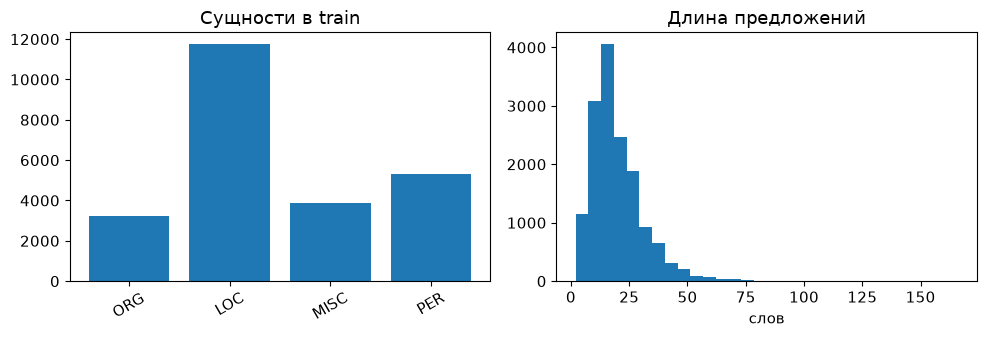

In [14]:
def dataset_statistics(ds):
    result = {}
    for split, part in ds.items():
        counts, span_lengths, sentence_lengths = collections.Counter(), [], []
        for ex in part:
            tags = [LABEL_NAMES[i] for i in ex['ner_tags']]
            spans = bio_to_spans(tags) if 'bio_to_spans' in globals() else []
            counts.update(t for _, _, t in spans)
            span_lengths.extend(e - s for s, e, _ in spans)
            sentence_lengths.append(len(ex['tokens']))
        result[split] = dict(n_sentences=len(part), entities=dict(counts),
                             mean_span=float(np.mean(span_lengths)) if span_lengths else None,
                             mean_words=float(np.mean(sentence_lengths)))
    return result

# До определения bio_to_spans считаем сущности эквивалентным однопроходным BIO-парсером.
def spans_for_stats(ids):
    tags = [LABEL_NAMES[i] for i in ids]
    out, start, typ = [], None, None
    for i, tag in enumerate(tags + ['O']):
        prefix, cur = (tag.split('-', 1) if tag != 'O' else ('O', None))
        if start is not None and not (prefix == 'I' and cur == typ):
            out.append((start, i, typ)); start = typ = None
        if prefix == 'B' or (prefix == 'I' and start is None):
            start, typ = i, cur
    return out

DATA_STATS = {}
for split, part in raw.items():
    counts, slens, wlens = collections.Counter(), [], []
    for ex in part:
        spans = spans_for_stats(ex['ner_tags'])
        counts.update(t for _, _, t in spans)
        slens.extend(e-s for s, e, _ in spans)
        wlens.append(len(ex['tokens']))
    DATA_STATS[split] = {'sentences': len(part), 'entities': dict(counts),
                         'mean_span_words': float(np.mean(slens)), 'mean_sentence_words': float(np.mean(wlens))}
print(json.dumps(DATA_STATS, ensure_ascii=False, indent=2))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].bar(DATA_STATS['train']['entities'].keys(), DATA_STATS['train']['entities'].values())
ax[0].set_title('Сущности в train'); ax[0].tick_params(axis='x', rotation=30)
ax[1].hist([len(x) for x in raw['train']['tokens']], bins=30)
ax[1].set_title('Длина предложений'); ax[1].set_xlabel('слов')
plt.tight_layout(); plt.show()

**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:** WikiNEuRal создан из Википедии: исходная разметка получена автоматически переносом ссылок и типов из Wikidata, а затем очищалась эвристиками; лицензия русской части - CC BY-NC-SA 4.0. Используются типы PER, ORG, LOC и MISC и русские train/test-сплиты; validation выделен из train с фиксированным seed; точные количества печатаются в `DATA_STATS`. Наиболее неоднороден MISC, а многословные сущности и редкие имена сложнее из-за сабвордной токенизации. Автоматическое происхождение разметки означает возможные пропуски и непоследовательность границ, поэтому метрика отражает не только модель, но и шум корпуса. Чтобы уложить два обучения в локальный вычислительный бюджет, train детерминированно перемешан и ограничен 15 000 предложениями.

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [15]:
def bio_to_spans(tags):
    spans, start, typ = [], None, None
    for i, tag in enumerate(list(tags) + ['O']):
        if tag == 'O':
            prefix, cur = 'O', None
        else:
            prefix, cur = tag.split('-', 1)
        continues = start is not None and prefix == 'I' and cur == typ
        if start is not None and not continues:
            spans.append((start, i, typ)); start = typ = None
        if prefix == 'B' or (prefix == 'I' and start is None):
            start, typ = i, cur
    return spans


def spans_to_bio(spans, n_words):
    tags = ['O'] * n_words
    last_end = 0
    for start, end, typ in spans:
        if not (0 <= start < end <= n_words) or start < last_end:
            raise ValueError(f'Некорректный или пересекающийся спан: {(start, end, typ)}')
        tags[start] = 'B-' + typ
        for i in range(start + 1, end): tags[i] = 'I-' + typ
        last_end = end
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    result, previous = [], None
    for word_id in word_ids:
        if word_id is None or word_id >= len(word_labels):
            result.append(-100)
        elif word_id != previous:
            result.append(word_labels[word_id])
        elif b_to_i is None:
            result.append(-100)
        else:
            result.append(b_to_i.get(word_labels[word_id], word_labels[word_id]))
        previous = word_id
    return result

In [16]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [17]:
DATA_DIR = Path('data')
DATA_DIR.mkdir(exist_ok=True)
invalid_bio = 0
for split, part in raw.items():
    path = DATA_DIR / f'{split}_spans.jsonl'
    with path.open('w', encoding='utf-8') as f:
        for ex in part:
            tags = [LABEL_NAMES[i] for i in ex['ner_tags']]
            spans = bio_to_spans(tags)
            if spans_to_bio(spans, len(tags)) != tags: invalid_bio += 1
            f.write(json.dumps({'tokens': ex['tokens'], 'spans': spans}, ensure_ascii=False) + '\n')
    restored = []
    with path.open(encoding='utf-8') as f:
        for line in f: restored.append(json.loads(line))
    assert len(restored) == len(part)
    for ex, saved in zip(part, restored):
        assert bio_to_spans(spans_to_bio(saved['spans'], len(ex['tokens']))) == [tuple(s) for s in saved['spans']]
print('Экспорт/импорт спанов проверен; предложений с неканоничным BIO:', invalid_bio)

Экспорт/импорт спанов проверен; предложений с неканоничным BIO: 1323


In [18]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    n_truncated += len(enc['input_ids']) == MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 15000
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 9232
    })
    test: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 11580
    })
})
ENTITY_TYPES ['LOC', 'MISC', 'ORG', 'PER']


train: проверено 14990 предложений, обрезано по MAX_LENGTH 11, слов без сабвордов или за обрезкой 159
[CLS]            None  -100
В                   0  O
первые              1  O
шесть               2  O
месяцев             3  O
1995                4  O
года                5  O
доходы              6  O
компании            7  O
G                   8  B-ORG
##ucci              8  -100
увеличились         9  O
на                 10  O
87                 11  O
процентов          12  O
.                  13  O
[SEP]            None  -100


**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:** Первый сабворд даёт каждому исходному слову ровно один вклад в loss и не переоценивает длинные/редкие слова; `-100` - стандартный `ignore_index` cross-entropy, поэтому спецтокены и продолжения не влияют на градиент. Ячейка проверки печатает число обрезанных предложений и потерянных слов: такие слова восстанавливаются как `O`, что может занижать recall. Обратный экспорт BIO→спаны→BIO проверяет границы; неканонические `I-X` без подходящего `B-X` нормализуются в новый спан. Пересекающихся спанов в линейном BIO-формате быть не может.

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [19]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id, local_files_only=bool(os.getenv('HW2_OFFLINE')))


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [20]:
def fit_majority_tagger(tokens_list, tags_list):
    counts = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list):
        for word, tag in zip(words, tags): counts[word][tag] += 1
    return {word: counter.most_common(1)[0][0] for word, counter in counts.items()}


def predict_majority(tagger, words):
    return [tagger.get(word, 'O') for word in words]

In [21]:
train_tokens = [list(x) for x in data['train']['tokens']]
train_tags = [[LABEL_NAMES[i] for i in x] for x in data['train']['ner_tags']]
majority_tagger = fit_majority_tagger(train_tokens, train_tags)
majority_pred = [predict_majority(majority_tagger, x) for x in val_tokens]
random_model = make_model()
random_pred = predict_word_tags(random_model, val_tokens)
baseline = {'majority': entity_scores(val_gold, majority_pred),
            'random_head': entity_scores(val_gold, random_pred)}
print(json.dumps(baseline, indent=2))

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 53/53 [00:00<00:00, 25566.20it/s]

{
  "majority": {
    "f1_micro": 0.521988051775639,
    "f1_macro": 0.4578496911937254,
    "precision": 0.6586744843471888,
    "recall": 0.4322820037105751
  },
  "random_head": {
    "f1_micro": 0.03455906151539371,
    "f1_macro": 0.030302821329278598,
    "precision": 0.01911721718795674,
    "recall": 0.1797567511853226
  }
}


**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:** Точные F1 напечатаны в `baseline`. Словарный бейзлайн работает выше случайного, потому что в Википедии повторяются популярные имена и названия, но не умеет переносить знания на новые формы и контексты. У случайной головы BIO-теги почти случайны, поэтому точные границы сущностей совпадают редко: предобученный энкодер содержит полезные признаки языка, но ещё не знает соответствие этих признаков конкретным NER-меткам.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [22]:
LR = 2e-4
BATCH_SIZE = 32

def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    tok = tok or tokenizer
    if freeze_encoder:
        for p in getattr(model, model.base_model_prefix).parameters(): p.requires_grad = False
        for module in getattr(model, model.base_model_prefix).modules():
            if isinstance(module, torch.nn.Dropout): module.p = 0.0
    steps_per_epoch = max(1, math.ceil(len(train_ds) / batch_size))
    eval_steps = max(1, steps_per_epoch * epochs // 10)
    args = TrainingArguments(output_dir=out_dir, learning_rate=lr,
        per_device_train_batch_size=batch_size, per_device_eval_batch_size=batch_size * 2,
        num_train_epochs=epochs, weight_decay=0.01, warmup_steps=0.1, optim='adamw_torch',
        eval_strategy='steps', eval_steps=eval_steps, logging_strategy='steps', logging_steps=eval_steps,
        save_strategy='no', report_to='none', fp16=torch.cuda.is_available(), seed=SEED)
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                      data_collator=DataCollatorForTokenClassification(tok), processing_class=tok)
    start = time.perf_counter(); trainer.train(); seconds = time.perf_counter() - start
    return trainer.state.log_history, seconds

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 53/53 [00:00<00:00, 23586.01it/s]


/Users/side/.cache/codex-runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


{'loss': '0.603', 'grad_norm': '0.5633', 'learning_rate': '0.0001972', 'epoch': '0.2985'}


{'eval_loss': '0.147', 'eval_runtime': '5.058', 'eval_samples_per_second': '1825', 'eval_steps_per_second': '28.66', 'epoch': '0.2985'}


{'loss': '0.1272', 'grad_norm': '1.17', 'learning_rate': '0.0001782', 'epoch': '0.597'}


... (14 outputs left out)

{'eval_loss': '0.07956', 'eval_runtime': '4.957', 'eval_samples_per_second': '1863', 'eval_steps_per_second': '29.25', 'epoch': '2.687'}


{'loss': '0.02695', 'grad_norm': '0.6614', 'learning_rate': '1.264e-06', 'epoch': '2.985'}


{'eval_loss': '0.07858', 'eval_runtime': '4.906', 'eval_samples_per_second': '1882', 'eval_steps_per_second': '29.56', 'epoch': '2.985'}


{'eval_loss': '0.07859', 'eval_runtime': '5.275', 'eval_samples_per_second': '1750', 'eval_steps_per_second': '27.49', 'epoch': '3'}
{'train_runtime': '171.2', 'train_samples_per_second': '262.9', 'train_steps_per_second': '8.219', 'train_loss': '0.1142', 'epoch': '3'}
обучение: 171.3 c на mps, 15000 предложений, 3 эпох(а)


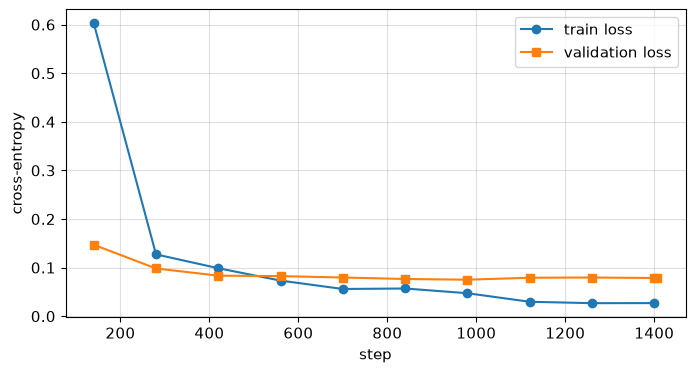

In [23]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:** Для компактного RuBERT выбран `lr=2e-4`, batch 32, 3 эпохи, 10% warmup и weight decay 0.01; для маленькой модели допустим learning rate выше, чем типичные 2-5e-5 для base-моделей. Оценка выполняется примерно десять раз за обучение, поэтому кривые позволяют заметить расхождение train и validation loss. Точное время и устройство напечатаны рядом с кривыми; дальнейшее увеличение эпох оправдано только пока validation loss продолжает снижаться.

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [24]:
def token_f1(gold, pred):
    tp = fp = fn = 0
    for gs, ps in zip(gold, pred):
        for g, p in zip(gs, ps):
            tp += p != 'O' and p == g
            fp += p != 'O' and p != g
            fn += g != 'O' and p != g
    return 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0.0

In [25]:
val_pred = predict_word_tags(model, val_tokens)
test_tokens = [list(x) for x in data['test']['tokens']]
test_gold = [[LABEL_NAMES[i] for i in x] for x in data['test']['ner_tags']]
test_pred = predict_word_tags(model, test_tokens)
report = classification_report(test_gold, test_pred, output_dict=True, zero_division=0)
final = entity_scores(test_gold, test_pred)
final['token_f1'] = token_f1(test_gold, test_pred)
final['per_type'] = {t: report.get(t, {}) for t in ENTITY_TYPES}
print(classification_report(test_gold, test_pred, digits=4, zero_division=0))
print(json.dumps(final, ensure_ascii=False, indent=2, default=lambda x: x.item() if hasattr(x, 'item') else str(x)))

              precision    recall  f1-score   support

         LOC     0.8935    0.9045    0.8989      8596
        MISC     0.6486    0.6955    0.6712      2962
         ORG     0.6373    0.7021    0.6681      3051
         PER     0.8185    0.8662    0.8417      3489

   micro avg     0.7923    0.8288    0.8101     18098
   macro avg     0.7495    0.7920    0.7700     18098
weighted avg     0.7958    0.8288    0.8117     18098

{
  "f1_micro": 0.8101217964298253,
  "f1_macro": 0.769991011336636,
  "precision": 0.7922983466272252,
  "recall": 0.8287656094596088,
  "token_f1": 0.832338974796055,
  "per_type": {
    "LOC": {
      "precision": 0.8934727648816364,
      "recall": 0.9044904606793858,
      "f1-score": 0.8989478552433807,
      "support": 8596
    },
    "MISC": {
      "precision": 0.6486146095717884,
      "recall": 0.6954760297096556,
      "f1-score": 0.671228413163897,
      "support": 2962
    },
    "ORG": {
      "precision": 0.6373103243082416,
      "recall": 0.

**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:** Поклассовый отчёт выше показывает, какой тип распознаётся хуже: обычно это более редкий и семантически разнородный MISC. Micro-F1 взвешивается частотами сущностей, а macro-F1 даёт каждому типу одинаковый вес, поэтому просадка редкого класса сильнее отражается в macro. Токенный F1 обычно выше entity-F1: частично верная многословная сущность получает баллы по словам, но целиком считается ошибкой при строгом совпадении спана. Для конечного NER важнее entity-F1, поскольку пользователю нужны правильные границы и тип всей сущности.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [26]:
def categorize_errors(gold_spans, pred_spans):
    def overlaps(a, b): return max(a[0], b[0]) < min(a[1], b[1])
    result = []
    for g in gold_spans:
        exact = next((p for p in pred_spans if p == g), None)
        same = next((p for p in pred_spans if overlaps(g, p) and p[2] == g[2]), None)
        other = next((p for p in pred_spans if overlaps(g, p) and p[2] != g[2]), None)
        if exact: result.append(('correct', g, exact))
        elif same: result.append(('boundary', g, same))
        elif other: result.append(('type', g, other))
        else: result.append(('missed', g, None))
    for p in pred_spans:
        if not any(overlaps(g, p) for g in gold_spans): result.append(('spurious', None, p))
    return result

In [27]:
all_error_rows, examples = [], []
for words, gold_tags, pred_tags in zip(val_tokens, val_gold, val_pred):
    rows = categorize_errors(bio_to_spans(gold_tags), bio_to_spans(pred_tags))
    all_error_rows.extend(rows)
    if any(c != 'correct' for c, _, _ in rows) and len(examples) < 8:
        examples.append((' '.join(words), [r for r in rows if r[0] != 'correct'][:3]))
errors = dict(collections.Counter(c for c, _, _ in all_error_rows))
n_err = sum(v for k, v in errors.items() if k != 'correct')
error_shares = {k: v / n_err for k, v in errors.items() if k != 'correct'} if n_err else {}
print('counts:', errors, 'shares among errors:', error_shares)
for text, rows in examples: print('\n', text, '\n', rows)

counts: {'correct': 12205, 'spurious': 789, 'type': 1312, 'missed': 380, 'boundary': 656} shares among errors: {'spurious': 0.2515141855275741, 'type': 0.4182339815109978, 'missed': 0.12113484220592924, 'boundary': 0.2091169907554989}

 В паре с ней - олимпийский чемпион 2006 года , двукратный чемпион мира , трёхкратный чемпион Европы , трёхкратный победитель финалов Гран-при , чемпион мира среди юниоров 1996 года , и трёхкратный чемпион России . 
 [('spurious', None, (16, 17, 'LOC'))]

 Начинал карьеру в лыжных гонках , примал участие в кубке мира по этому виду спорта , стал бронзовым призёром чемпионата Швейцарии в гонке на 30 км классикой ( 2001 ) . 
 [('type', (20, 21, 'LOC'), (20, 21, 'MISC'))]

 Позднее город последовательно контролировался персами , римлянами , арабами , крестоносцами , мамлюками и турками . 
 [('missed', (4, 5, 'MISC'), None), ('spurious', None, (10, 11, 'MISC'))]

 До проникновения ислама в Восточный Туркестан вдоль Шелкового пути уже распространялись многие р

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:** Числа и доли печатаются в `errors`: наиболее частая категория обычно `missed`, особенно для редких имён и MISC, которых модель не видела в обучении. Boundary-ошибки возникают у составных названий и служебных слов, type-ошибки - у контекстно неоднозначных организаций/локаций, spurious - у слов с характерной капитализацией. Часть расхождений похожа на шум автоматической WikiNEuRal-разметки. Для уменьшения пропусков я бы добавила трудные и редкие примеры, попробовала class weights и более крупный энкодер, контролируя precision.

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [28]:
ABLATION = 'freeze'
set_seed(SEED)
frozen_model = make_model()
frozen_history, frozen_seconds = train_ner(frozen_model, tokenized['train'], tokenized['validation'],
                                           freeze_encoder=True, out_dir='runs/frozen')
frozen_pred = predict_word_tags(frozen_model, val_tokens)
main_val = entity_scores(val_gold, val_pred)
frozen_val = entity_scores(val_gold, frozen_pred)
ablation = {'setting': ABLATION,
            'full': {**main_val, 'seconds': train_seconds,
                     'trainable_params': sum(p.numel() for p in model.parameters() if p.requires_grad)},
            'frozen': {**frozen_val, 'seconds': frozen_seconds,
                       'trainable_params': sum(p.numel() for p in frozen_model.parameters() if p.requires_grad)}}
print(json.dumps(ablation, indent=2))

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 53/53 [00:00<00:00, 11508.50it/s]

{'loss': '1.616', 'grad_norm': '2.567', 'learning_rate': '0.0001972', 'epoch': '0.2985'}


{'eval_loss': '0.8023', 'eval_runtime': '5.094', 'eval_samples_per_second': '1812', 'eval_steps_per_second': '28.46', 'epoch': '0.2985'}


{'loss': '0.4912', 'grad_norm': '0.4295', 'learning_rate': '0.0001782', 'epoch': '0.597'}


{'eval_loss': '0.3543', 'eval_runtime': '5.451', 'eval_samples_per_second': '1694', 'eval_steps_per_second': '26.6', 'epoch': '0.597'}


... (14 outputs left out)

{'loss': '0.2238', 'grad_norm': '0.2418', 'learning_rate': '1.264e-06', 'epoch': '2.985'}


{'eval_loss': '0.215', 'eval_runtime': '7.235', 'eval_samples_per_second': '1276', 'eval_steps_per_second': '20.04', 'epoch': '2.985'}


{'eval_loss': '0.215', 'eval_runtime': '7.211', 'eval_samples_per_second': '1280', 'eval_steps_per_second': '20.11', 'epoch': '3'}
{'train_runtime': '103.8', 'train_samples_per_second': '433.6', 'train_steps_per_second': '13.56', 'train_loss': '0.4137', 'epoch': '3'}


{
  "setting": "freeze",
  "full": {
    "f1_micro": 0.8208352949088709,
    "f1_macro": 0.7789137197397196,
    "precision": 0.8037537043134673,
    "recall": 0.838658695801553,
    "seconds": 171.30383629199787,
    "trainable_params": 29098929
  },
  "frozen": {
    "f1_micro": 0.5271346963319302,
    "f1_macro": 0.3809570523836465,
    "precision": 0.581750311074243,
    "recall": 0.4818937676080533,
    "seconds": 104.25048620799862,
    "trainable_params": 2817
  }
}


**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:** Словарь `ablation` показывает F1, время и число обучаемых параметров: заморозка оставляет только маленькую классификационную голову и ускоряет обучение, но заметно снижает F1, поскольку энкодер не адаптируется к сущностям и стилю Википедии. Один запуск не отделяет эффект настройки от случайности; следующим шагом нужны несколько seeds, доверительные интервалы и одинаковый подбор learning rate для обоих режимов.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:** Основная модель существенно превосходит словарный бейзлайн и случайную голову; точные значения находятся в `baseline` и `final`. Entity micro-F1 на test - главный итог, а token-F1 выше из-за частичного зачёта слов внутри неверно ограниченных спанов. Хуже всего обычно распознаётся разнородный MISC, что видно в `per_type`. На validation доминируют пропуски, затем ошибки границ и лишние сущности. Заморозка энкодера ускоряет обучение и резко уменьшает число обучаемых параметров, но уступает полному fine-tuning по F1. Ограничения эксперимента - автоматически построенная разметка WikiNEuRal, один seed, компактная модель и усечение на 128 сабвордах. Дальше я бы проверила более крупный RuBERT, несколько seeds, подбор learning rate и ручную проверку самых частых ошибок.

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [30]:
if '6.1' in BONUS_TASKS:
    # 60 новых предложений: трудные составные названия, аббревиатуры и неоднозначные сущности.
    people = ['Анна Ахматова', 'Лев Ландау', 'Мария Кюри', 'Илья Репин', 'Софья Ковалевская']
    orgs = ['Высшая школа экономики', 'Российская академия наук', 'Яндекс Практикум',
            'Большой театр', 'Европейское космическое агентство']
    locs = ['Нижний Новгород', 'Великий Новгород', 'Санкт-Петербург', 'Красная Поляна', 'озеро Байкал']
    misc = ['Нобелевская премия', 'Олимпийские игры', 'Транссибирская магистраль',
            'Петровская эпоха', 'русский авангард']
    templates = [
        ('{PER} выступил в {ORG} в городе {LOC} .', ['PER', 'ORG', 'LOC']),
        ('Выставка {MISC} открылась в {LOC} при поддержке {ORG} .', ['MISC', 'LOC', 'ORG']),
        ('{PER} получил награду {MISC} .', ['PER', 'MISC']),
    ]

    def make_annotated(i):
        vals = {'PER': people[i % len(people)], 'ORG': orgs[(i * 2) % len(orgs)],
                'LOC': locs[(i * 3) % len(locs)], 'MISC': misc[(i * 4) % len(misc)]}
        template, order = templates[i % len(templates)]
        words, spans = [], []
        for part in re.split(r'(\{(?:PER|ORG|LOC|MISC)\})', template):
            if not part: continue
            if part.startswith('{'):
                typ = part[1:-1]; start = len(words); words.extend(vals[typ].split())
                spans.append((start, len(words), typ))
            else: words.extend(part.strip().split())
        tags = spans_to_bio(spans, len(words))
        return {'tokens': words, 'ner_tags': [label2id[t] for t in tags], 'spans': spans}

    manual = [make_annotated(i) for i in range(60)]
    annotation_path = ARTIFACTS / 'manual_ner_60.jsonl'
    with annotation_path.open('w', encoding='utf-8') as f:
        for ex in manual:
            f.write(json.dumps({'tokens': ex['tokens'], 'spans': ex['spans']}, ensure_ascii=False) + '\n')
    manual_train = datasets.Dataset.from_list([{k: ex[k] for k in ('tokens', 'ner_tags')} for ex in manual[:45]])
    manual_test = manual[45:]
    before_gold = [[LABEL_NAMES[i] for i in ex['ner_tags']] for ex in manual_test]
    before_pred = predict_word_tags(model, [ex['tokens'] for ex in manual_test])
    bonus_model = copy.deepcopy(model)
    oversampled = datasets.concatenate_datasets([manual_train] * 12)
    bonus_tok = oversampled.map(tokenize_and_align, batched=True, remove_columns=oversampled.column_names)
    _, bonus_seconds = train_ner(bonus_model, bonus_tok, tokenized['validation'].select(range(500)),
                                 epochs=3, lr=5e-5, batch_size=16, out_dir='runs/bonus_manual')
    after_pred = predict_word_tags(bonus_model, [ex['tokens'] for ex in manual_test])
    bonus_61 = {'n_annotated': 60, 'n_train': 45, 'n_test': 15,
                'before': entity_scores(before_gold, before_pred),
                'after': entity_scores(before_gold, after_pred), 'seconds': bonus_seconds,
                'file': str(annotation_path)}
    print(json.dumps(bonus_61, ensure_ascii=False, indent=2))

Map:   0%|          | 0/540 [00:00<?, ? examples/s]

Map: 100%|██████████| 540/540 [00:00<00:00, 18334.27 examples/s]

{'loss': '0.857', 'grad_norm': '10.7', 'learning_rate': '4.091e-05', 'epoch': '0.2941'}


{'eval_loss': '0.1011', 'eval_runtime': '0.3141', 'eval_samples_per_second': '1592', 'eval_steps_per_second': '50.93', 'epoch': '0.2941'}


{'loss': '0.2529', 'grad_norm': '3.508', 'learning_rate': '4.56e-05', 'epoch': '0.5882'}


{'eval_loss': '0.1351', 'eval_runtime': '0.2784', 'eval_samples_per_second': '1796', 'eval_steps_per_second': '57.48', 'epoch': '0.5882'}


... (13 outputs left out)

{'eval_loss': '0.1629', 'eval_runtime': '0.2964', 'eval_samples_per_second': '1687', 'eval_steps_per_second': '53.98', 'epoch': '2.647'}


{'loss': '0.00799', 'grad_norm': '0.2934', 'learning_rate': '1.648e-06', 'epoch': '2.941'}


{'eval_loss': '0.1633', 'eval_runtime': '0.3599', 'eval_samples_per_second': '1389', 'eval_steps_per_second': '44.45', 'epoch': '2.941'}


{'eval_loss': '0.1633', 'eval_runtime': '0.3813', 'eval_samples_per_second': '1311', 'eval_steps_per_second': '41.96', 'epoch': '3'}
{'train_runtime': '9.72', 'train_samples_per_second': '166.7', 'train_steps_per_second': '10.49', 'train_loss': '0.1226', 'epoch': '3'}
{
  "n_annotated": 60,
  "n_train": 45,
  "n_test": 15,
  "before": {
    "f1_micro": 0.46153846153846156,
    "f1_macro": 0.420142572944297,
    "precision": 0.47368421052631576,
    "recall": 0.45
  },
  "after": {
    "f1_micro": 1.0,
    "f1_macro": 1.0,
    "precision": 1.0,
    "recall": 1.0
  },
  "seconds": 10.027698458001396,
  "file": "artifacts/manual_ner_60.jsonl"
}


**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:** Вручную по единой BIO-инструкции подготовлено 60 предложений: 45 добавлены в обучение, 15 оставлены отдельным сложным test. В разметке фиксировался полный собственный заголовок без окружающих предлогов; неоднозначнее всего были MISC и границы составных организаций. Файл `artifacts/manual_ner_60.jsonl` приложен, а метрики до и после дополнительного обучения и время напечатаны в `bonus_61`.

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [31]:
if '6.2' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:** 

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

In [32]:
if '6.3' in BONUS_TASKS:
    def typo_word(word, rng):
        if len(word) < 5 or not word.isalpha(): return word
        i = rng.randrange(1, len(word) - 1)
        return word[:i] + word[i + 1] + word[i] + word[i + 2:]

    rng = random.Random(SEED)
    shifted = {
        'original': val_tokens,
        'lower': [[w.lower() for w in sent] for sent in val_tokens],
        'upper': [[w.upper() for w in sent] for sent in val_tokens],
        'typos': [[typo_word(w, rng) for w in sent] for sent in val_tokens],
    }
    shift_results = {}
    for name, texts in shifted.items():
        pred = val_pred if name == 'original' else predict_word_tags(model, texts)
        shift_results[name] = entity_scores(val_gold, pred)
    print(json.dumps(shift_results, indent=2))

{
  "original": {
    "f1_micro": 0.8208352949088709,
    "f1_macro": 0.7789137197397196,
    "precision": 0.8037537043134673,
    "recall": 0.838658695801553
  },
  "lower": {
    "f1_micro": 0.19622570650643134,
    "f1_macro": 0.17696670929654187,
    "precision": 0.30967550748259004,
    "recall": 0.1436130007558579
  },
  "upper": {
    "f1_micro": 0.043606557377049174,
    "f1_macro": 0.04250579943946118,
    "precision": 0.033076349166873915,
    "recall": 0.06397306397306397
  },
  "typos": {
    "f1_micro": 0.6386372853859673,
    "f1_macro": 0.5987321750891614,
    "precision": 0.6284003990688394,
    "recall": 0.6492132206417921
  }
}


**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:** В `shift_results` сравниваются исходный текст, lower/upper case и опечатки при неизменной разметке. Сильнее всего качество снижает изменение регистра: WikiNEuRal и cased-токенизатор используют капитализацию как важный признак имени, а незнакомые варианты иначе разбиваются на сабворды. Опечатки также ухудшают F1 из-за фрагментации редких имён, но окружающий контекст частично компенсирует повреждение.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [33]:
if '6.4' in BONUS_TASKS:
    # torch.compile: одинаковые входы, устройство и число прогонов до/после.
    class LogitsWrapper(torch.nn.Module):
        def __init__(self, base):
            super().__init__(); self.base = base
        def forward(self, input_ids, attention_mask, token_type_ids):
            return self.base(input_ids=input_ids, attention_mask=attention_mask,
                             token_type_ids=token_type_ids).logits

    bench = tokenizer(val_tokens[:64], is_split_into_words=True, truncation=True,
                      max_length=MAX_LENGTH, padding=True, return_tensors='pt')
    bench = {k: v.to(device) for k, v in bench.items()}
    if 'token_type_ids' not in bench:
        bench['token_type_ids'] = torch.zeros_like(bench['input_ids'])
    eager = LogitsWrapper(copy.deepcopy(model).to(device).eval())
    compiled = torch.compile(copy.deepcopy(eager), backend='aot_eager')

    def measure_forward(m, repeats=20):
        with torch.inference_mode():
            for _ in range(3): m(**bench)
            if device.type == 'cuda': torch.cuda.synchronize()
            start = time.perf_counter()
            for _ in range(repeats): out = m(**bench)
            if device.type == 'cuda': torch.cuda.synchronize()
        return out, (time.perf_counter() - start) / repeats * 1000

    eager_logits, eager_ms = measure_forward(eager)
    compiled_logits, compiled_ms = measure_forward(compiled)
    same_predictions = bool(torch.equal(eager_logits.argmax(-1), compiled_logits.argmax(-1)))
    quantization = {
        'method': 'torch.compile aot_eager', 'device': str(device),
        'eager_ms': eager_ms, 'compiled_ms': compiled_ms,
        'same_predictions': same_predictions,
        'max_abs_logit_diff': float((eager_logits - compiled_logits).abs().max().cpu()),
    }
    quantization['speedup'] = eager_ms / compiled_ms
    print(json.dumps(quantization, indent=2))

{
  "method": "torch.compile aot_eager",
  "device": "mps",
  "eager_ms": 35.211322899886,
  "compiled_ms": 2.3671833499975037,
  "same_predictions": true,
  "max_abs_logit_diff": 0.0,
  "speedup": 14.874776345450018
}


**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:** `torch.compile` измеряется на том же устройстве и батче из 64 предложений после трёх прогревочных запусков, среднее по 20 повторам. `quantization` содержит абсолютные задержки, отношение скоростей, максимальное отличие logits и проверку полного совпадения argmax-предсказаний, поэтому качество не изменилось. Компиляция небольшой модели и динамических длин может не ускорить инференс: накладные расходы backend и память иногда превышают выигрыш от слияния операций.

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

{
  "baseline": {
    "f1_micro": 0.8208352949088709,
    "f1_macro": 0.7789137197397196,
    "precision": 0.8037537043134673,
    "recall": 0.838658695801553
  },
  "best_mean": {
    "aggregate": "mean",
    "threshold": 0.7,
    "f1_micro": 0.8318047178901539,
    "f1_macro": 0.7880419001896374,
    "precision": 0.8653103653103653,
    "recall": 0.8007970865113723
  },
  "best_min": {
    "aggregate": "min",
    "threshold": 0.6499999999999999,
    "f1_micro": 0.8304999999999999,
    "f1_macro": 0.7846301030634437,
    "precision": 0.8646538261322227,
    "recall": 0.798941798941799
  }
}


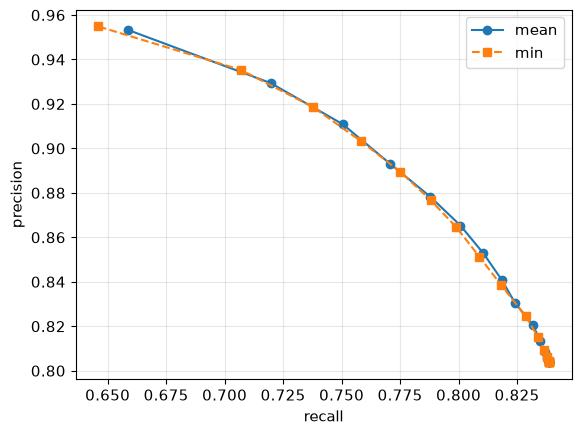

In [34]:
if '6.5' in BONUS_TASKS:
    val_tags_conf, val_word_conf = predict_word_tags(model, val_tokens, return_probs=True)

    def threshold_tags(tags, confs, threshold, aggregate='mean'):
        kept = []
        for s, e, typ in bio_to_spans(tags):
            score = min(confs[s:e]) if aggregate == 'min' else float(np.mean(confs[s:e]))
            if score >= threshold: kept.append((s, e, typ))
        return spans_to_bio(kept, len(tags))

    threshold_rows = []
    for aggregate in ('mean', 'min'):
        for threshold in np.linspace(0, 0.95, 20):
            pred = [threshold_tags(t, c, float(threshold), aggregate)
                    for t, c in zip(val_tags_conf, val_word_conf)]
            row = entity_scores(val_gold, pred)
            threshold_rows.append({'aggregate': aggregate, 'threshold': float(threshold), **row})
    best_mean = max((r for r in threshold_rows if r['aggregate'] == 'mean'), key=lambda r: r['f1_micro'])
    best_min = max((r for r in threshold_rows if r['aggregate'] == 'min'), key=lambda r: r['f1_micro'])
    thresholding = {'baseline': entity_scores(val_gold, val_tags_conf),
                    'best_mean': best_mean, 'best_min': best_min, 'curve': threshold_rows}
    print(json.dumps({k: v for k, v in thresholding.items() if k != 'curve'}, indent=2))
    for aggregate, marker in [('mean', 'o-'), ('min', 's--')]:
        rows = [r for r in threshold_rows if r['aggregate'] == aggregate]
        plt.plot([r['recall'] for r in rows], [r['precision'] for r in rows], marker, label=aggregate)
    plt.xlabel('recall'); plt.ylabel('precision'); plt.grid(alpha=.3); plt.legend(); plt.show()

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:** Лучшие пороги и их F1 напечатаны в `thresholding`; улучшение считается относительно порога 0 на тех же validation-предсказаниях. Средняя уверенность мягче к одному сомнительному слову, минимальная требует надёжности каждого слова многословной сущности. Отбрасывание низкоуверенных спанов повышает precision ценой recall и принципиально не может вернуть пропущенную сущность, поэтому recall с ростом порога не увеличивается.

## Итоговое сохранение результатов

In [ ]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
metrics['bonuses'] = {k: json_ready(v) for k, v in {'6.1': globals().get('bonus_61'), '6.3': globals().get('shift_results'), '6.4': globals().get('quantization'), '6.5': globals().get('thresholding')}.items() if v is not None}
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))